In [ ]:
# Hosted D2L setup: fetch the exact helper module used to build this notebook.
from pathlib import Path
from urllib.request import urlretrieve
from importlib.metadata import PackageNotFoundError, version
import importlib.util, os, subprocess, sys

required = ['numpy', 'pandas', 'matplotlib', 'requests', 'scipy', 'pillow', 'regex', 'torch', 'torchvision']
imports = {'pillow': 'PIL'}
pinned = {}
fallbacks = {'torch': 'torch==2.11.0', 'torchvision': 'torchvision==0.26.0'}
device = os.environ.get("D2L_HOSTED_DEVICE", "auto").lower()
if device not in ("auto", "cpu", "gpu"):
    raise ValueError(f"Invalid D2L_HOSTED_DEVICE={device!r}")
if device == "auto":
    try:
        gpu = (Path("/dev/nvidia0").exists() or
               subprocess.run(["nvidia-smi", "-L"], capture_output=True,
                              timeout=5).returncode == 0)
    except (FileNotFoundError, subprocess.SubprocessError):
        gpu = False
else:
    gpu = device == "gpu"
if not gpu:
    os.environ.setdefault("CUDA_VISIBLE_DEVICES", "-1")
    os.environ.setdefault("JAX_PLATFORMS", "cpu")
tensorflow_version = None
if 'pytorch' in ("tensorflow", "jax"):
    try:
        tensorflow_version = version("tensorflow")
    except PackageNotFoundError:
        pass
# Colab's CPU image currently carries a CUDA-enabled TensorFlow wheel. Its
# first ordinary tensor operation probes CUDA and emits an error-level cuInit
# diagnostic. JAX notebooks also use TensorFlow for data loading, so overlay
# the matching CPU build in both CPU variants. Keep the provider's
# ``tensorflow`` distribution metadata: other preinstalled Colab packages
# depend on that distribution name, while both wheels expose the same module.
if not gpu and 'pytorch' in ("tensorflow", "jax"):
    try:
        tensorflow_cpu_version = version("tensorflow-cpu")
    except PackageNotFoundError:
        tensorflow_cpu_version = None
    if (tensorflow_version is not None and
            tensorflow_cpu_version != tensorflow_version):
        subprocess.check_call([
            sys.executable, "-m", "pip", "install", "-q", "--no-deps",
            f"tensorflow-cpu=={tensorflow_version}",
        ])
if "tf-keras" in fallbacks and tensorflow_version is not None:
    fallbacks["tf-keras"] = f"tf-keras=={tensorflow_version}"
missing = []
for package in required:
    if package in pinned:
        wanted, cpu_requirement, gpu_requirement, match = pinned[package]
        requirement = gpu_requirement if gpu else cpu_requirement
        if requirement is None:  # a GPU-only package on a CPU runtime
            continue
        try:
            installed = version(package)
        except PackageNotFoundError:
            installed = None
        actual = (installed.split("+", 1)[0]
                  if installed is not None and match == "public" else installed)
        if actual != wanted:
            missing.append(requirement)
    elif importlib.util.find_spec(imports.get(package, package)) is None:
        missing.append(fallbacks.get(package, package))
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])

mismatched = []
for package, (wanted, cpu_requirement, _, match) in pinned.items():
    if not gpu and cpu_requirement is None:
        continue
    try:
        installed = version(package)
    except PackageNotFoundError:
        installed = None
    actual = (installed.split("+", 1)[0]
              if installed is not None and match == "public" else installed)
    if actual != wanted:
        mismatched.append(f"{package}={installed!r} (expected {wanted})")
if mismatched:
    raise RuntimeError("Hosted runtime setup failed: " + ", ".join(mismatched))

root = Path(".d2l-hosted") / "46d487bb9b699b97c7c5fc5edd866e4d2ad7919b"
package = root / "d2l"
package.mkdir(parents=True, exist_ok=True)
base = "https://raw.githubusercontent.com/smolix/d2l-neu/46d487bb9b699b97c7c5fc5edd866e4d2ad7919b/d2l"
for name in ('__init__.py', 'torch.py'):
    target = package / name
    if not target.exists():
        urlretrieve(f"{base}/{name}", target)
if str(root.resolve()) not in sys.path:
    sys.path.insert(0, str(root.resolve()))
pythonpath = os.environ.get("PYTHONPATH", "").split(os.pathsep)
if str(root.resolve()) not in pythonpath:
    os.environ["PYTHONPATH"] = os.pathsep.join(
        [str(root.resolve()), *[entry for entry in pythonpath if entry]]
    )


# Decoding and Generation

So far in this chapter, we have judged language models strictly by how well
they assign probabilities to the next token. To *generate* text, however, a
model must also select a concrete token at each step from its predicted
distribution—and this decision matters far more than one might expect, because
different selection rules cause the very same model to produce dramatically
different prose. In that section, we saw the simplest rule fall
short: greedily picking the single most probable token at every step rapidly
traps the generator in repetitive loops. How, then, should we turn next-token
distributions into fluent text?

The algorithm that converts a sequence of next-token distributions into output
tokens is called *decoding* [@Graves.2013; @Holtzman.Buys.Du.ea.2020], and
decoding strategies fall into two broad families. *Maximization* algorithms
search for an output sequence with high joint probability under the model,
whereas *sampling* algorithms draw each token stochastically after reshaping
or pruning the unreliable tail of the distribution. Below, we develop and
compare both families in turn. Crucially, every decoding rule interacts with
the language model solely through its next-token distribution, so the
algorithms we build here apply unchanged to any autoregressive language
model—whether an RNN, a state space model, or a Transformer.

In [1]:
import math
import numpy as np
import torch
from torch import nn
from torch.nn import functional as F
from d2l import torch as d2l

## The Decoding Problem

A trained language model supplies next-token conditional distributions: given
any prefix $x_{<t} = x_1, \ldots, x_{t-1}$, it outputs $P(x_t \mid x_{<t})$,
and by the chain rule of probability (that section), these
conditionals define the joint probability of any complete sequence via
$P(x_1, \ldots, x_T) = \prod_{t=1}^{T} P(x_t \mid x_{<t})$.

Decoding poses the inverse problem: given those conditionals, which sequence
should we emit? At first glance, finding the *most probable* sequence seems
like the obvious goal, yet exact maximization is completely intractable. Over
a vocabulary $\mathcal{V}$ and horizon $T$, there are $|\mathcal{V}|^T$
possible continuations—for our 1,027-token vocabulary and a 50-token
continuation, $1027^{50} > 10^{150}$ candidates, far beyond anything we could
ever enumerate. Every practical decoder must therefore explore only a tiny
slice of the search tree, deciding at each step which prefixes to retain.

Even if exact search were feasible, the single highest-probability sequence is
frequently *not* what we want. When a task admits only a narrow band of
correct outputs, such as transcribing speech or translating a technical
sentence, seeking a high-probability sequence works well. By contrast, when
many continuations are equally valid—as in dialogue or creative writing—each
individual continuation necessarily carries tiny probability mass, because a
well-calibrated model spreads probability across many plausible trajectories.
Forcing the model to pick the single most probable path destroys that natural
variety, whereas sampling preserves it by drawing directly from the learned
distribution.

the figure organizes decoding strategies along this
divide. Maximization methods (greedy decoding and beam search) remain the
standard choice for constrained tasks with few valid outputs, while
sampling methods augmented with temperature scaling or truncation are the
default for open-ended generation.

![Two families of decoding rules. Searching for high-probability sequences suits tasks with few acceptable outputs; sampling preserves diversity in open-ended generation.](https://raw.githubusercontent.com/smolix/d2l-neu/notebooks/img/mdl-rnn-decoding-taskmap.svg)

### A Model to Decode From

For our experiments, we use the concise RNN language model from
that section: 512-dimensional embeddings, 128 hidden units,
dropout on both embeddings and hidden states, and an output layer over the
1,027 BPE tokens of *The Time Machine*. We begin by loading the 32-token
training and validation windows from `d2l.TimeMachine`.

In [2]:
data = d2l.TimeMachine(batch_size=1024, num_steps=32)

Next, we construct the concise recurrent cell `d2l.RNN` and language model
`d2l.RNNLM` with $d = 512$, $h = 128$, dropout, and learning rate `lr=4`.

In [3]:
rnn = d2l.RNN(num_inputs=512, num_hiddens=128)
model = d2l.RNNLM(rnn, vocab_size=len(data.vocab), lr=4, dropout=0.5,
                  emb_dropout=0.1)

Training `model` for 10 epochs with gradient clipping at `gradient_clip_val=1`
reproduces a validation perplexity near 60 on *The Time Machine*.

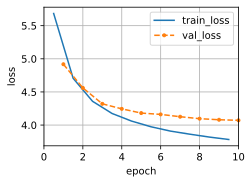

validation perplexity 58.7


In [4]:
trainer = d2l.Trainer(max_epochs=10, gradient_clip_val=1, num_gpus=1)
trainer.fit(model, data)
print(f'validation perplexity {math.exp(trainer.history["val_loss"][-1]):.1f}')

Every decoding algorithm in this section accesses the language model through a
single model-agnostic interface `step_fn(ids)` that takes the prefix token ids
so far and returns a 1-D NumPy vector of next-token logits. Returning plain
NumPy arrays lets us write every decoder once across all four frameworks, and
omitting any explicit hidden state is deliberate: any autoregressive model,
recurrent or Transformer, fits this exact signature.

In [5]:
model.eval()  # Dropout off

def seq_logits(ids):  # Token ids in, NumPy logits at every position out
    with torch.inference_mode():
        logits = model(d2l.tensor([ids], device=d2l.try_gpu()))
    return d2l.numpy(logits)[0]

def step_fn(ids):  # Token ids in, NumPy logits for the next token out
    return seq_logits(ids)[-1]

The trade-off is efficiency: each call re-evaluates the network across the
*entire* prefix just to extract one vector of logits. For an RNN, that extra
work is avoidable, and we return to its computational cost at the end of the
section.

## Greedy Decoding

The simplest possible decoder commits at every step to the single token with
highest conditional probability:

$$x_t = \operatorname*{argmax}_{x \in \mathcal{V}} P(x \mid x_{<t}).$$

Score the prefix, pick the argmax, append it, and repeat. Greedy decoding
requires just one model evaluation per generated token and is completely
deterministic—the same prefix always yields the exact same continuation. The
helper `show` below decodes token ids into a quoted string, displaying line
breaks as `\n` and replacing any unprintable bytes with `U+FFFD`.

In [6]:
def show(ids):  # Decoded text as a literal; control characters -> U+FFFD
    text = data.tokenizer.decode(ids)
    return repr(''.join(c if c.isprintable() or c == '\n' else '\ufffd'
                        for c in text))

def decode_greedy(text, num_tokens=50):
    ids = data.tokenizer.encode(text)
    for _ in range(num_tokens):
        ids.append(int(step_fn(ids).argmax()))
    return ids

for text in ('The Time Traveller', 'It seemed to me that'):
    d2l.print_wrapped(show(decode_greedy(text)))

"The Time Traveller.\n\n'I had\nfrom the\nsidea.\n\n'I had\nfrom
    the\nsidea.\n\n'I had\nfrom the\nsidea.\n\n'I had\nf"


"It seemed to me that\ntheir.\n\n'I had\nfrom the\nsidea.\n\n'I had\nfrom
    the\nsidea.\n\n'I had\nfrom the\nsidea.\n\n'I"


Just as in that section, both continuations quickly collapse into
repetitive loops. Two structural weaknesses are built into greedy decoding.
The first is *myopia*: stringing together locally optimal choices does not
necessarily yield the globally optimal sequence. Suppose the model assigns
first-token probabilities $P(A) = 0.5$ and $P(B) = 0.4$, followed by an
uncertain second step after $A$ (top continuation probability $0.3$) but a
highly confident step after $B$ (top probability $0.9$). Greedy decoding
immediately commits to $A$ and finishes with joint probability
$0.5 \times 0.3 = 0.15$, missing the far more probable sequence beginning with
$B$ at $0.4 \times 0.9 = 0.36$ (the figure).

![The myopia of greedy decoding on a two-step example. Greedy decoding takes the more probable first token $A$ and ends with the sequence $AC$ at joint probability $0.5 \times 0.3 = 0.15$. The path through $B$, which it never explores, reaches $0.4 \times 0.9 = 0.36$.](https://raw.githubusercontent.com/smolix/d2l-neu/notebooks/img/mdl-rnn-greedy-myopia.svg)

The second weakness is repetition itself. Because greedy decoding feeds its
own deterministic argmax back into the recurrence at every step, the next
hidden state is a deterministic function of the current state; once the
trajectory falls into an attracting cycle, there is no randomness to knock it
out. Nor is this merely a quirk of our small RNN:
@Holtzman.Buys.Du.ea.2020 demonstrated the exact same *neural text
degeneration* in language models a thousand times larger, showing that
likelihood maximization on open-ended text consistently yields repetitive,
bland prose noticeably unlike human writing.

## Beam Search

Whereas greedy decoding commits immediately to a single path and exhaustive
search retains every possible path, *beam search* strikes a controlled middle
ground parameterized by a single hyperparameter—the *beam width* $w$. At every
step, beam search keeps the $w$ highest-scoring prefixes alive. Starting from
the $w$ most probable first tokens, each subsequent step expands every
surviving prefix across the vocabulary, scores all $w \cdot |\mathcal{V}|$
candidate extensions by their cumulative log-probability, and prunes back down
to the top $w$ sequences. Setting $w = 1$ recovers greedy decoding, while
letting $w$ grow large enough that no candidate is ever pruned recovers
exhaustive search.

![Beam search with beam width 2 over a five-token vocabulary. At every step each surviving prefix is expanded over the whole vocabulary and only the two highest-scoring prefixes are kept; the survivors here are $A$ and $C$, then $AB$ and $CE$, then $ABD$ and $CED$.](https://raw.githubusercontent.com/smolix/d2l-neu/notebooks/img/mdl-rnn-beam-tree.svg)

the figure illustrates beam search with $w = 2$ over a
five-token vocabulary $\mathcal{V} = \{A, B, C, D, E\}$ across three steps
(suppressing the shared prompt from the notation). Suppose $A$ and $C$ are the
two most probable first tokens. At step 2, we score all ten extensions
$x' \in \mathcal{V}$,

$$
\begin{aligned}
P(A, x') &= P(A)\, P(x' \mid A),\\
P(C, x') &= P(C)\, P(x' \mid C),
\end{aligned}
$$

and retain the top two, say $AB$ and $CE$, repeating the same expansion at step
3 to keep $ABD$ and $CED$. Rather than scoring all $5^3 = 125$ sequences, beam
search evaluates only $5 + 10 + 10 = 25$. In general, generating $T$ tokens
costs $O(w |\mathcal{V}| T)$—just $w$ times the cost of greedy decoding and
exponentially less than exhaustive search.

When sequences are allowed to terminate early by emitting an end-of-sequence
token, comparing candidates of different lengths requires a length correction.
Because every token log-probability is non-positive, raw cumulative
log-probability monotonically decreases as a sequence grows, unfairly favoring
short hypotheses. The standard remedy is *length normalization*
[@Wu.Schuster.Chen.ea.2016], scoring a candidate that adds $T$ tokens to
a prefix of length $t_0$ by

$$\frac{1}{T^\beta} \sum_{t=t_0+1}^{t_0+T} \log P(x_t \mid x_{<t}),$$

where the exponent $\beta$ (typically around $0.75$) interpolates between
unnormalized log-probability ($\beta = 0$) and per-token average
log-probability ($\beta = 1$); in the code below, we name this argument
`alpha` following @Wu.Schuster.Chen.ea.2016 .

The `beam_search` implementation below carries completed hypotheses (those
ending in `eos_id`) forward untouched while expanding only active beams. Note
one clean optimization: because the overall top $w$ candidates can include at
most $w$ extensions of any single prefix, we only need to take the top $w$
next tokens from each active beam rather than sorting all $|\mathcal{V}|$
extensions.

In [7]:
def beam_search(step_fn, prefix, num_tokens, beam_size=4,
                alpha=0.75, eos_id=None):
    """Length-normalized beam search (score = log P / len^alpha).
    Returns candidates sorted best-first; [0][1] is the argmax sequence."""
    def log_softmax(logits):
        logits = [float(l) for l in logits]
        m = max(logits)
        lse = m + math.log(sum(math.exp(l - m) for l in logits))
        return [l - lse for l in logits]
    score = lambda logp, ids: logp / max(1, len(ids) - len(prefix))**alpha
    beams = [(0.0, list(prefix), False)]  # (log-prob, sequence, finished)
    for _ in range(num_tokens):
        if all(done for _, _, done in beams):
            break
        candidates = [b for b in beams if b[2]]  # Finished pass through
        for logp, ids, _ in (b for b in beams if not b[2]):
            logprobs = log_softmax(step_fn(ids))
            best = sorted(range(len(logprobs)),
                          key=lambda i: -logprobs[i])[:beam_size]
            candidates += [(logp + logprobs[i], ids + [i], i == eos_id)
                           for i in best]
        beams = sorted(candidates, key=lambda b: score(b[0], b[1]),
                       reverse=True)[:beam_size]
    return sorted([(score(logp, ids), ids) for logp, ids, _ in beams],
                  reverse=True)

Let us decode the same two prompts with $w = 1$ (reproducing greedy decoding)
and $w = 4$, printing the length-normalized score the equation
of the top hypothesis. Since our corpus has no end-of-sequence token, all
candidates reach length 30 and the constant denominator
$30^{0.75} \approx 12.8$ leaves their relative ranking unchanged.

In [8]:
for text in ('The Time Traveller', 'It seemed to me that'):
    prefix = data.tokenizer.encode(text)
    for w in (1, 4):
        score, ids = beam_search(step_fn, prefix, 30, beam_size=w)[0]
        d2l.print_wrapped(f'w={w}, score {score:.2f}: {show(ids)}')

w=1, score -4.13: "The Time Traveller.\n\n'I had\nfrom the\nsidea.\n\n'I
    had\nfrom the\nsidea.\n"
w=4, score -3.43: "The Time Traveller.\n\n'Then I had\ndeliculture.\n\n'Then
    I had\ndeliculture.\n"
w=1, score -4.21: "It seemed to me that\ntheir.\n\n'I had\nfrom
    the\nsidea.\n\n'I had\nfrom the\nside"


w=4, score -3.60: "It seemed to me that it was a\npossibly.\n\n'As I saw
    a\npossibly.\n\n'As"


Expanding the beam generally discovers higher-probability continuations than
greedy decoding—though not with certainty, since approximate pruning can still
discard a prefix that would have paid off later. Yet higher probability does
not automatically equate to *better* prose: on open-ended generation, beam
search in large language models produces text markedly more repetitive than
human writing [@Holtzman.Buys.Du.ea.2020], a contrast we quantify shortly.
By contrast, on tightly constrained tasks such as speech recognition and
machine translation, beam search with a modest width (typically 4 to 10)
remains the standard decoder
[@Sutskever.Vinyals.Le.2014; @Wu.Schuster.Chen.ea.2016].

## Sampling

If our model has learned a reasonable distribution over continuations, the
most natural alternative to maximization is direct *ancestral sampling*: draw
$x_t \sim P(x_t \mid x_{<t})$, append it, and repeat. Sampling restores the
rich variety that maximization suppresses, but raw sampling runs straight into
a tail problem. Because the softmax assigns nonzero probability to every entry
in the vocabulary (a thousand tokens here, and over a hundred thousand in
modern LLMs), the tiny probabilities across thousands of implausible tokens add
up to a substantial collective mass at every step. Consequently, pure sampling
regularly draws a wildly implausible token, and feeding that token back in as
context can derail the rest of the passage—the exact rollout error compounding
discussed in that section. @Holtzman.Buys.Du.ea.2020 termed
this the *unreliable tail*: a language model's probabilities are well
calibrated near the head of the distribution, yet noisy far down the tail. The
practical remedy is to reshape or truncate the distribution before sampling,
and four widely used controls accomplish this in distinct ways.

**Temperature scaling** divides every logit $o_x$ by a positive scalar
$\tau > 0$ prior to the softmax:

$$P_\tau(x \mid x_{<t}) = \frac{\exp(o_x / \tau)}{\sum_{x' \in \mathcal{V}} \exp(o_{x'} / \tau)} \propto P(x \mid x_{<t})^{1/\tau}.$$

Lowering $\tau$ below 1 sharpens the distribution (converging to greedy
decoding as $\tau \to 0$), whereas raising $\tau$ above 1 flattens it toward
uniform. Because temperature rescales the entire distribution uniformly,
however, it is a blunt instrument: cooling the softmax enough to suppress the
unreliable tail simultaneously collapses legitimate diversity among plausible
head tokens.

**Top-$k$ sampling** truncates by rank, keeping only the $k$ most probable
tokens, renormalizing, and sampling
[@Fan.Lewis.Dauphin.2018; @Radford.Wu.Child.ea.2019]. **Top-$p$** (or
*nucleus*) sampling truncates by cumulative probability mass instead,
retaining the smallest head of tokens whose probabilities sum to at least $p$
(commonly $p = 0.9$) [@Holtzman.Buys.Du.ea.2020]. This distinction
matters because the model's entropy fluctuates dramatically from token to
token: when the next word is nearly certain, a fixed $k = 20$ lets in nineteen
poor candidates, whereas when dozens of words are equally natural, $k = 20$
may clip genuine variety. Top-$p$ adapts dynamically, shrinking its candidate
set on peaked distributions and widening it on flat ones, though it can still
behave overly greedily when a single top token exceeds $p$ (e.g., probability
$0.95$ under $p = 0.9$, excluding a solid runner-up).

**Min-$p$ sampling** sets the threshold relative to the model's top
probability [@Nguyen.Baker.Neo.ea.2025], retaining every token whose
probability is at least $p_{\min}$ times that of the single most likely token
(for instance, $p_{\min} = 0.05$). When the model is confident, the cutoff
rises automatically and admits only strong contenders; when the model is
uncertain, the cutoff lowers to allow broader exploration.
@Nguyen.Baker.Neo.ea.2025 show that this relative threshold degrades
far more gracefully than top-$p$ at elevated temperatures, where an absolute
mass threshold sweeps in much of the flattened tail.

### A Unified Sampler

Because temperature, top-$k$, top-$p$, and min-$p$ all operate on the exact
same next-token distribution, a single compact function handles every
combination. Below, `sample_next` returns the greedy argmax when
`temperature == 0`, and otherwise forms $P_\tau$ via the equation,
sorts tokens in descending probability order, computes how many leading tokens
each active cutoff permits, keeps the tightest bound, renormalizes, and draws
one token using a NumPy random generator `rng`.

In [9]:
def sample_next(logits, temperature=1.0, k=None, p=None, min_p=None,
                rng=None):
    """Draw a token id from 1-D NumPy logits; temperature 0 is greedy.
    Top-k, top-p, and min-p truncate the temperature-scaled distribution."""
    logits = np.asarray(logits, dtype=np.float64)
    if temperature == 0:
        return int(logits.argmax())
    probs = np.exp((logits - logits.max()) / temperature)
    order = np.argsort(-probs)               # token ids, most probable first
    probs = probs[order] / probs.sum()
    keep = len(probs)
    if k is not None:                        # top-k: a fixed count
        keep = min(keep, k)
    if p is not None:                        # top-p: smallest head of mass p
        keep = min(keep, int(np.searchsorted(probs.cumsum(), p)) + 1)
    if min_p is not None:                    # min-p: a fraction of the top
        keep = min(keep, int((probs >= min_p * probs[0]).sum()))
    rng = np.random.default_rng() if rng is None else rng
    return int(order[rng.choice(keep, p=probs[:keep] / probs[:keep].sum())])

The wrapper `generate` packages the autoregressive decoding loop: call
`step_fn`, draw the next token with `sample_next` (forwarding any strategy
keyword arguments), append it, and terminate early if `eos_id` is emitted.
Because open-ended prose from *The Time Machine* has no end-of-sequence token,
our examples generate a fixed number of tokens.

In [10]:
def generate(step_fn, prefix, num_tokens, eos_id=None, **strategy):
    """Extend prefix by up to num_tokens ids, each chosen by sample_next
    from step_fn(ids), the next-token logits; stop early at eos_id."""
    ids = list(prefix)
    for _ in range(num_tokens):
        ids.append(sample_next(step_fn(ids), **strategy))
        if eos_id is not None and ids[-1] == eos_id:
            break
    return ids

A five-token toy distribution with probabilities $0.45, 0.25, 0.15, 0.10$, and
$0.05$ lets us verify each cutoff directly: top-$k$ with $k = 2$ retains only
tokens 0 and 1; top-$p$ with $p = 0.8$ retains tokens 0, 1, and 2 (whose
cumulative mass reaches $0.85$); and min-$p$ with $p_{\min} = 0.5$ retains
tokens with probability at least $0.5 \times 0.45 = 0.225$, again tokens 0
and 1. Drawing 1,000 samples under each rule confirms the exact support.

In [11]:
logits = np.log([0.45, 0.25, 0.15, 0.10, 0.05])
print('greedy:', sample_next(logits, temperature=0))
for cutoff in (dict(k=2), dict(p=0.8), dict(min_p=0.5)):
    drawn = {sample_next(logits, **cutoff) for _ in range(1000)}
    print(cutoff, 'tokens drawn:', sorted(drawn))

greedy: 0
{'k': 2} tokens drawn: [0, 1]
{'p': 0.8} tokens drawn: [0, 1, 2]


{'min_p': 0.5} tokens drawn: [0, 1]


As expected, each rule samples strictly from its surviving support: tokens 0
and 1 for top-$k$ and min-$p$, and tokens 0 through 2 for top-$p$.

### Cutoffs on a Trained Model

To see how these three rules behave on a real language model, let us plot our
RNN's sorted next-token distribution following `"The Time Traveller"` on
log–log axes. Viewed this way, each truncation rule has a clean geometric
interpretation: top-$k$ draws a fixed vertical line at rank $k$ regardless of
the curve's shape; top-$p$ draws a vertical line at whichever rank accumulates
probability mass $p$; and min-$p$ draws a *horizontal* line at $p_{\min}$
times the top probability, rising and falling with the model's confidence.
Everything to the right of a vertical cutoff, or beneath the horizontal cutoff,
is pruned away.

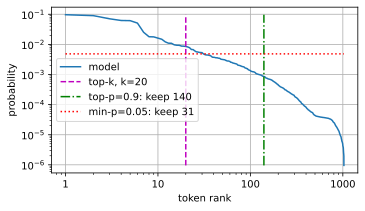

In [12]:
def next_probs(text):  # Next-token probabilities after text, sorted
    logits = step_fn(data.tokenizer.encode(text))
    probs = np.exp(logits - logits.max())
    return np.sort(probs / probs.sum())[::-1]

def cutoffs(probs, p=0.9, min_p=0.05):  # Tokens kept by top-p and min-p
    return (int(np.searchsorted(probs.cumsum(), p)) + 1,
            int((probs >= min_p * probs[0]).sum()))

probs = next_probs('The Time Traveller')
n_p, n_m = cutoffs(probs)
lo, hi = probs[-1], probs[0]
d2l.plot([np.arange(1, len(probs) + 1), [20, 20], [n_p, n_p],
          [1, len(probs)]], [probs, [lo, hi], [lo, hi], [0.05 * hi] * 2],
         xlabel='token rank', ylabel='probability', xscale='log',
         yscale='log', figsize=(5.5, 3),
         legend=['model', 'top-k, k=20', f'top-p=0.9: keep {n_p}',
                 f'min-p=0.05: keep {n_m}'])

On log–log axes, the sorted probabilities fall steadily from between $0.1$ and
$0.25$ at rank 1 down to about $10^{-3}$ near rank 100 before plunging more steeply
across the remaining hundreds of tokens—the vast low-probability tail that
truncation removes. To observe how adaptively each rule responds to model
confidence, we compare `"The Time Traveller"` against the shorter prefix
`"The Time"`, which is followed by `" Traveller"` in 11 of its 13 occurrences
in the novella and therefore yields a sharply peaked distribution.

In [13]:
for text in ('The Time Traveller', 'The Time'):
    probs = next_probs(text)
    n_p, n_m = cutoffs(probs)
    print(f'{text!r}: top probability {probs[0]:.2f}; kept: top-k 20, '
          f'top-p {n_p}, min-p {n_m}')

'The Time Traveller': top probability 0.10; kept: top-k 20, top-p 140, min-p 31
'The Time': top probability 0.69; kept: top-k 20, top-p 6, min-p 2


While top-$k$ rigidly retains 20 tokens regardless of context, both adaptive
rules contract sharply once the model is confident: after `"The Time"`, where
the top token dominates, both prune aggressively, with min-$p$ retaining only
a handful of candidates. When the model is uncertain after `"The Time
Traveller"`, however, the two diverge: top-$p$ must reach deep into the tail
to accumulate 90% of the mass—admitting well over a hundred tokens, most
individually below 1%—whereas min-$p$ anchors solely on the leading candidate,
retaining at most a few dozen tokens within a factor of twenty of the top
probability.

### Strategies Compared on One Prefix

Let us inspect the actual continuations produced by each strategy, starting
with pure temperature scaling at $\tau = 0.5$, $1.0$, and $2.0$.

In [14]:
prefix = data.tokenizer.encode('The Time Traveller')
for tau in (0.5, 1.0, 2.0):
    out = generate(step_fn, prefix, 50, temperature=tau)
    d2l.print_wrapped(f'tau={tau}: {show(out)}')

tau=0.5: "The Time Traveller pale of the\ndelight of\nthe lamp and\npresent
    bushes.\n\n'I had\npresently\nmetinessed\nof a time. I felt\nwhich\n"
tau=1.0: "The Time Traveller.'\n\n'From the powersing solack, and silent it
    would by vanished! I came gave me to me.\n\n'I took with me up of
    them?ly dancing ru"
tau=2.0: 'The Time Traveller went co tsprockated d�ir can� stoelt-lice slow
    against\nich�ined to hished theirsentantworld in dararact disItvesj�
    perllow\nWild5ise?3 seemed'


At $\tau = 0.5$, the sampler stays conservatively close to high-probability
tokens; at $\tau = 1.0$, outputs become noticeably more varied and occasionally
slip into garbled words; and at $\tau = 2.0$, flattening the distribution lets
tail tokens overwhelm the stream, breaking out of English and even emitting
byte sequences that fail to form valid UTF-8 characters. Next, we compare our
main decoding strategies head to head on the same prompt at their standard
settings.

In [15]:
strategies = {'greedy': dict(temperature=0), 'tau=1': dict(),
              'top-k=20': dict(k=20), 'top-p=0.9': dict(p=0.9),
              'min-p=0.05': dict(min_p=0.05)}
for name, strategy in strategies.items():
    out = generate(step_fn, prefix, 50, **strategy)
    d2l.print_wrapped(f'{name:>10}: {show(out)}')

    greedy: "The Time Traveller.\n\n'I had\nfrom the\nsidea.\n\n'I had\nfrom
    the\nsidea.\n\n'I had\nfrom the\nsidea.\n\n'I had\nf"
     tau=1: 'The Time Traveller, and sgat; so like a sttyj dayshindting,
    posserent and buth on that Gecting it leve against\nbut7 Sa crying\ndark
    weight at first'
  top-k=20: "The Time Traveller looked round in these gone. His animals
    had\nsoon.\n\n'I wood to see some\nthe Psychologist in\nmank, and I
    directive, and my hand. I was in"
 top-p=0.9: 'The Time Traveller rarements. Then I thought "As of trift his
    ownisterse of the Palace of Gallen Proburned this white.\n\n\'Chen my an
    exton.\n'


min-p=0.05: "The Time Traveller came to pates of\nbit\nmels. Then\n'Then.
    As\nbefore a bigroud of these chambuge steading\ninsmination. I"


Naturally, a small single-layer RNN trained on one novella cannot produce
flawless prose under any decoder, and a single sample per rule is noisy
evidence. Even so, the qualitative contrast is unmistakable: greedy decoding
is deterministic and falls into a repeating cycle, whereas every sampler
produces fresh, non-looping text on every call. In practice, combining a
moderate temperature with top-$p$ or min-$p$ truncation balances fluency and
diversity well and serves as the default for open-ended generation.

## Evaluation and Cost

### The Quality of Generated Text

Beyond eyeballing individual passages, how can we compare decoding strategies
systematically? Perplexity cannot answer this question: perplexity evaluates
the *model* on held-out human text, not a particular decoding rule, and
scoring generated samples by their own model likelihood would tautologically
crown maximization the winner even though sampling deliberately trades peak
likelihood for diversity.

Automated diagnostics can nonetheless pinpoint specific failure modes. To
quantify repetition, we use *distinct-3*—the ratio of unique 3-grams to total
3-grams in a generated continuation, equal to 1 when no three-token span ever
repeats and approaching 0 when text locks into a cycle. Below, we generate
100-token continuations from 20 random six-token validation prefixes under
greedy decoding, beam search ($w = 4$), and each sampler, reporting both mean
per-token log-probability under the model and mean distinct-3.

In [16]:
def log_prob(ids, start):  # Mean log-probability of ids[start:] in one pass
    logits = seq_logits(ids[:-1])[start - 1:]
    lse = logits.max(1) + np.log(np.exp(logits - logits.max(1, keepdims=True)).sum(1))
    return float(np.mean(logits[np.arange(len(logits)), ids[start:]] - lse))

def distinct(ids, n=3):  # Fraction of distinct n-grams in ids
    grams = [tuple(ids[i:i + n]) for i in range(len(ids) - n + 1)]
    return len(set(grams)) / len(grams)

val = d2l.numpy(data.X[data.num_train:data.num_train + data.num_val])
rows = np.random.default_rng().choice(len(val), 20, replace=False)
prefixes = [[int(i) for i in val[r, :6]] for r in rows]
decoders = {
    'greedy': lambda pre: generate(step_fn, pre, 100, temperature=0),
    'beam, w=4': lambda pre: beam_search(step_fn, pre, 100, beam_size=4)[0][1],
    'tau=1': lambda pre: generate(step_fn, pre, 100),
    'top-k=20': lambda pre: generate(step_fn, pre, 100, k=20),
    'top-p=0.9': lambda pre: generate(step_fn, pre, 100, p=0.9),
    'min-p=0.05': lambda pre: generate(step_fn, pre, 100, min_p=0.05)}
for name, decode in decoders.items():
    outs = [decode(pre) for pre in prefixes]
    print(f'{name:>10}: log-prob per token '
          f'{np.mean([log_prob(o, 6) for o in outs]):.2f}, distinct-3 '
          f'{np.mean([distinct(o[6:]) for o in outs]):.2f}')

    greedy: log-prob per token -1.89, distinct-3 0.15


 beam, w=4: log-prob per token -1.46, distinct-3 0.19


     tau=1: log-prob per token -3.93, distinct-3 0.99


  top-k=20: log-prob per token -2.83, distinct-3 0.99


 top-p=0.9: log-prob per token -3.38, distinct-3 0.99


min-p=0.05: log-prob per token -2.78, distinct-3 0.98


The two metrics pull cleanly in opposite directions. Both maximization
strategies achieve markedly higher per-token log-probability than any sampler
(with beam search typically edging out greedy decoding), yet their distinct-3
scores plunge because they repeat most of their 3-grams. All four samplers
achieve distinct-3 near 1, reproducing on a miniature scale the exact
likelihood-versus-diversity trade-off documented by
@Holtzman.Buys.Du.ea.2020 .

Within the sampling family, diversity is nearly saturated across all four
rules, while per-token log-probability cleanly separates them. Pure ancestral
sampling ($\tau = 1$) incurs the lowest average log-probability (around $-4$
nats per token), whereas all three truncated samplers raise likelihood
substantially without sacrificing distinct-3. Consistent with our earlier
cutoff counts, top-$p$ ($0.9$) sits closest to pure sampling because it
retains the broadest support, while top-$k$ ($20$) and min-$p$ ($0.05$) prune
more aggressively and boost per-token log-probability by roughly a full
nat—demonstrating directly that tail truncation works as intended.

Automatic metrics like distinct-3 are valuable for catching concrete failure
modes, yet they cannot measure coherence, factuality, or style. Ultimately,
open-ended text generation is judged by human readers (or calibrated proxy
evaluators), while constrained tasks with ground-truth references such as
translation can be measured against reference outputs. In short, perplexity
guides *model* selection, whereas human preference—or task-specific
benchmarks—guides *decoder* selection.

### The Cost of Generation

Because we kept `step_fn` stateless so that it could wrap any autoregressive
model, every newly generated token re-runs the RNN over the *entire* prefix,
making a $T$-token continuation cost $O(T^2)$ cell updates. Autoregressive
generation is also inherently *sequential*: unlike teacher-forced training,
where all positions are known up front, token $t + 1$ cannot be scored until
token $t$ has been chosen. While that sequential dependency is fundamental,
the quadratic recomputation is completely unnecessary for an RNN: because the
hidden state already summarizes the prefix, carrying that state forward from
step to step (as `predict` did in that section) brings the cost
down to exactly one cell update per token, independent of sequence length.
Models without a recurrent state avoid the same recomputation by caching what
they computed for each past token, at a memory cost that grows with the
length of the prefix (that section).

Constant compute and constant memory per generated token are the defining
efficiency advantages of recurrent language models. Yet that same fixed-size
state is also our model's bottleneck, forcing everything remembered from the
prefix through just 128 floating-point numbers
(that section). No decoding trick can coax nuance out
of a model whose next-token distributions fail to capture long-range
structure—though because our decoders treat the model purely as a black box,
every algorithm developed here transfers unchanged to far stronger models.

With this, Part *Basics* draws to a close—and it closes right on a sharp
architectural boundary. Our RNN predicts text one token at a time at constant
cost, yet it effectively uses only the last two or three tokens of history
(that section), and with gradients that vanish within a handful
of steps (that section) it has little chance of learning to use many
more. Two paths lead forward from here.
The first retains a fixed-size state while redesigning the recurrence so that
gradients survive across long horizons (that section). The second
abandons fixed-size compression altogether, retaining representations of every
past token and attending directly across them at a cost that grows with
sequence length—the *attention* mechanism (that section) at the
heart of modern large language models. Whichever architecture lies underneath,
the subword tokenizers, bits-per-byte evaluation, and decoding algorithms of
this chapter carry directly over.

## Summary

Decoding converts a language model's next-token distributions into concrete
token sequences. Maximization methods seek high-probability outputs: greedy
decoding commits locally at each step and suffers from both myopia and
repetitive loops, while beam search tracks the top $w$ hypotheses at $w$ times
the cost (using length normalization when candidates can terminate early) and
excels on constrained tasks with narrow output spaces. For open-ended
generation, sampling preserves natural diversity, while temperature scaling
(the equation) and tail truncation via top-$k$, top-$p$, or min-$p$
prevent low-probability tail tokens from derailing the rollout—producing text
that matches pure sampling in distinct-3 diversity while remaining
substantially more probable. Finally, perplexity evaluates models rather than
decoders, and carrying a recurrent hidden state avoids the $O(T^2)$
recomputation of naive stateless decoding.

## Exercises

1. **Beam search properties.**
    1. Take beam width 2, the five-token vocabulary of
       the figure, and three steps. Assign conditional
       probabilities for which beam search does not return the most
       probable three-token sequence, and compute the probabilities of
       both sequences. What does your construction imply about how beam
       search can miss the most probable sequence?
    1. What is the smallest beam width that guarantees that beam search
       over $T$ steps returns the most probable of all
       $|\mathcal{V}|^T$ sequences, whatever the model?
    1. Let $w \leq |\mathcal{V}|$, and assume that no end-of-sequence
       token occurs. Count the calls to `step_fn` that `beam_search`
       makes over $T$ steps. Count also the calls that exhaustive search
       makes when it evaluates every prefix once. Evaluate both counts
       for $|\mathcal{V}| = 1{,}027$, $T = 50$, and $w = 4$.

1. [code] **Length normalization.** Run `beam_search` with $w = 4$ for up
   to 40 tokens after `'The Time Traveller'` and `'It seemed to me that'`.
   Pass the id of the newline character, `data.tokenizer.encode('\n')[0]`,
   as `eos_id`, and vary $\beta$ (the argument `alpha`) over
   $\{0, 0.75, 1.5\}$. Compare the lengths and the total log-probabilities
   of the winning candidates, and explain the trend using the equation.

1. **Truncation under temperature.** `sample_next` applies every
   cutoff to the temperature-scaled distribution $P_\tau$
   of the equation. Write the min-$p$ condition
   $P_\tau(x \mid x_{<t}) \geq p_{\min} \max_{x'} P_\tau(x' \mid x_{<t})$ as
   a condition on the untempered probabilities. For the five-token
   distribution 0.45, 0.25, 0.15, 0.10, 0.05, compute the sets that
   top-$k$ with $k = 2$, top-$p$ with $p = 0.85$, and min-$p$ with
   $p_{\min} = 0.5$ keep at $\tau = 2$. Which of the three rules keeps the
   same set at every temperature?

1. [code] **Top-$p$ versus min-$p$.** ● At $\tau = 1.5$, sweep $p$ for
   top-$p$ and $p_{\min}$ for min-$p$ over a grid of values. For each
   setting, generate 50-token continuations of five prefixes of your
   choice and record two averages over the generated tokens: the number
   of tokens the rule keeps, and the log-probability of the drawn token
   under the untempered model. Plot the second average against the
   first, one curve per rule. Which rule draws more probable tokens at
   the same average number of kept tokens? Compare your finding with
   those of @Nguyen.Baker.Neo.ea.2025 .

1. [code] **Constant cost per token.** ● `step_fn` re-runs the network over
   the entire prefix for every generated token, so a $T$-token
   continuation costs $O(T^2)$ cell
   updates (that section).
    1. Write a stateful replacement for `step_fn` that keeps the hidden
       state of `model.rnn` and consumes only the newest token, so that
       each call performs one cell update. Verify that `generate` produces
       the same greedy continuation with both versions.
    1. Time `generate` for 50, 200, and 800 tokens with both versions.
       Estimate from the ratios how each time grows with the number of
       tokens, and explain any departure from the quadratic and linear
       growth that the count of cell updates predicts.
    1. Why does the same replacement not carry over directly to
       `beam_search`, and what bookkeeping would make it work?

[Discussions](https://d2l.discourse.group/t/338)